# Домашнее задание: SFT для function calling

Qwen2.5-0.5B-Instruct умеет вызывать функции в формате `<tool_call>`, но наши пять функций умного дома видит
впервые и обращается с ними вольно. Дообучим её целиком (все веса) на диалогах с умным домом
и в конце посмотрим, как она управляет симулятором.

| Блок | Баллы |
|---|---|
| 1. До обучения: генерация через chat template | 1 |
| 2. Данные: разбор примера и роль каждого сообщения | 2 |
| 3. Маска loss: теги `{% generation %}` в шаблоне | 2 |
| 4. Обучение | 3 |
| 5. Оценка на тест-сете (дано) | 0 |
| 6. Агентный цикл | 2 |

Дано и менять не нужно: `smart_home.py` (симулятор и схемы пяти функций), `chat_ui.py` (чат),
`data/` с `train.jsonl`, `validation.jsonl` и `test_cases.jsonl`.
Ячейки для заполнения помечены `YOUR CODE HERE`.

## 0. Окружение

Берём Instruct-модель: формат `<tool_call>` и токен конца реплики `<|im_end|>` она уже знает,
учить будем поведению с конкретными функциями.

In [1]:
# Окружение: при первом запуске раскомментируй две строки ниже и перезапусти kernel (см. README.md).
# torch ставим именно с индекса cu126: колесо с PyPI по умолчанию собрано под CUDA 13 и требует драйвер >= 580.
# %pip install torch==2.8.0 --index-url https://download.pytorch.org/whl/cu126
# %pip install transformers==4.56.1 trl==0.23.1 datasets==3.6.0 accelerate==1.6.0 ipywidgets==8.1.9 matplotlib==3.10.1 pandas==2.2.3
import gc
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

from chat_ui import launch_chat
from smart_home import BASELINE_PROMPTS, SMART_HOME_TOOLS, SYSTEM_PROMPT, SmartHome

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("outputs/full_sft")
MAX_LENGTH = 2048

set_seed(SEED)
assert torch.cuda.is_available(), "Нужен GPU kernel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")

## 1. До обучения · 1 балл

Функция для модели — это JSON Schema: имя, описание, аргументы с типами и ограничениями.
Схемы передаются в `apply_chat_template` параметром `tools`: шаблон вставит их в system-реплику
и объяснит модели формат ответа `<tool_call>`. Посмотрим, что именно получает модель на вход.

In [2]:
print(json.dumps(SMART_HOME_TOOLS[0], ensure_ascii=False, indent=2))
print("=" * 80)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Turn on the kitchen light."},
]
print(tokenizer.apply_chat_template(messages, tools=SMART_HOME_TOOLS, tokenize=False, add_generation_prompt=True))

{
  "type": "function",
  "function": {
    "name": "turn_light",
    "description": "Switch a room light on or off. Ask for the room if unknown.",
    "parameters": {
      "type": "object",
      "properties": {
        "room": {
          "type": "string",
          "enum": [
            "kitchen",
            "bedroom",
            "living_room"
          ]
        },
        "state": {
          "type": "string",
          "enum": [
            "on",
            "off"
          ]
        }
      },
      "required": [
        "room",
        "state"
      ],
      "additionalProperties": false
    }
  }
}
<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"n

**Задание (1 балл).** Напишите `generate`: сообщения и схемы функций проходят через `apply_chat_template`
с `add_generation_prompt=True`, декодирование жадное, стоп на `<|im_end|>` (это `eos_token` токенизатора).
Верните только новые токены, без спецтокенов. Эта функция используется во всех следующих блоках.

In [ ]:
def generate(model, tokenizer, messages, tools, max_new_tokens=256):
    # YOUR CODE HERE
    inputs = tokenizer.apply_chat_template(
        messages, tools=tools, add_generation_prompt=True,
        tokenize=True, return_dict=True, return_tensors="pt",
    ).to(model.device)
    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False, temperature=None, top_p=None, top_k=None, repetition_penalty=1.0,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.pad_token_id,
        )
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


def answer(model, tokenizer, prompt):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    return generate(model, tokenizer, messages, SMART_HOME_TOOLS)

Формат модель знает, поэтому простые запросы отработает правильно. Смотрите на сложные: «Open the garage» —
модель подставляет в `turn_light` комнату `garage`, которой нет в схеме; «Turn off all lights» — придумывает
`room: "all"` вместо трёх вызовов; «Turn on the light» — выбирает комнату сама вместо уточняющего вопроса.
Запомним её ответы на десять запросов, после обучения сравним.

In [4]:
comparison = pd.DataFrame({"prompt": BASELINE_PROMPTS})
comparison["base"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

,prompt,base
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,Hello! How can I assist you with your smart home setup?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>"
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>"


## 2. Данные · 2 балла

Чтобы модель вызывала функции, покажем ей диалоги, где это делается правильно.
Одна строка JSONL — один диалог: `messages` и `tools`. Вызов функции — поле `tool_calls`
у реплики assistant, результат функции — отдельное сообщение с ролью `tool`.

In [5]:
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def show_dialog(messages):
    for message in messages:
        print(f"[{message['role']}] {message.get('content', '')}")
        for call in message.get("tool_calls") or []:
            arguments = json.dumps(call["function"]["arguments"], ensure_ascii=False)
            print(f"    -> {call['function']['name']}({arguments})")


train_rows = read_jsonl("data/train.jsonl")
validation_rows = read_jsonl("data/validation.jsonl")
print(f"train: {len(train_rows)}, validation: {len(validation_rows)}\n")

example = next(row for row in train_rows if any(m.get("tool_calls") for m in row["messages"]))
show_dialog(example["messages"])

train: 831, validation: 91

[system] You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.
[user] Сделай в гостиной 40 градусов, гости мерзнут
[assistant] Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?
[user] Хорошо, тогда максимум
[assistant] 
    -> set_temperature({"room": "living_room", "value": 30})
[tool] {"room": "living_room", "light": "off", "temperature": 30}
[assistant] Готово, в гостиной теперь 30 градусов.


В данных четыре типа диалогов. Примеры без вызова — не балласт: это единственное место, где модель видит,
что на неподдерживаемый запрос («открой гараж», «какая погода») нужно ответить отказом, а не подобрать
ближайшую функцию.

In [6]:
def scenario_type(row):
    calls_per_message = [len(m.get("tool_calls") or []) for m in row["messages"]]
    if sum(calls_per_message) == 0:
        return "no_call"
    if sum(n > 0 for n in calls_per_message) > 1:
        return "multi_turn"
    return "parallel_calls" if max(calls_per_message) > 1 else "single_call"


pd.DataFrame({
    "train": pd.Series([scenario_type(row) for row in train_rows]).value_counts(),
    "validation": pd.Series([scenario_type(row) for row in validation_rows]).value_counts(),
})

,train,validation
multi_turn,219,22
no_call,144,16
parallel_calls,145,15
single_call,323,38


Тот же диалог после шаблона — ровно такой текст модель увидит на обучении. `tool_calls` стали блоками
`<tool_call>` внутри реплики assistant, а результат функции — блоком `<tool_response>` внутри реплики
**user**: для модели это входящая информация, как и вопрос пользователя.

In [7]:
print(tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False))

<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "turn_light", "description": "Switch a room light on or off. Ask for the room if unknown.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "bedroom", "living_room"]}, "state": {"type": "string", "enum": ["on", "off"]}}, "required": ["room", "state"], "additionalProperties": false}}}
{"type": "function", "function": {"name": "set_temperature", "description": "Set an absolute room temperature in Celsius. For relative changes, obtain the current temperature first.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "

### Ваш разбор · 2 балла
Ответьте текстом по ячейкам выше:
- **1 балл.** В тексте после шаблона результат функции оказался внутри реплики **user**, а не assistant.
  Почему формат устроен так и что пошло бы не так, если бы модель училась предсказывать содержимое
  `<tool_response>` наравне со своими репликами?
- **1 балл.** По таблице типов сценариев: какой навык function calling даёт каждый из четырёх типов
  и чему модель не научится, если какой-то тип убрать из данных?

**1. Почему результат функции стоит во входящей реплике.**

То, что выводит функция зависит от внешнего мира, в нашем случае  это симулятор Smart Home. Модель только просит
выполнить действие и печатает <tool_call> и <|im_end|>, генерация останавливается, код выполняет
вызов и возвращает ответ. Для модели это наблюдение, то есть входящая информация, как вопрос пользователя.
Поэтому шаблон qwen кладет `<tool_response>` в реплику user, а несколько ответов подряд склеивает в одну
реплику. Модель этот текст читает и опирается на него, но сама никогда не генерирует.

Что пойдет не так:
- Модель учится выдумывать результаты вместо того, чтобы их получать. Ответ функции зависит от состояния дома,
  которого модель не видит. На обучении она научится сама дописывать правдоподобный ответ типа
  {"temperature": 21} и опираться на него, что как раз запрещает системный промпт (Do not invent missing
  arguments or claim actions without tool results) и то, зачем нужен вызов get_room_state перед
  отностельным изменением температуры.
- Цель для этих токенов по контексту предсказать нельзя, тк один и тот же вызов get_room_state(bedroom) в разных
  диалогах возвращает разные числа, ошибка value is out of range определяется валидатором симулятора.
  Градиент будет тянуть модель запоминать конкретные ответы симулятора из train, что по сути будет шумом, а не
  навыком, который понадобится на инференсе.
- Смещается баланс loss. В train и validation ответы функций занимают 42 тысячи токенов, собственные реплики
  ассистента 69 тысяч. Если учить и то и другое, то примерно 38 % сигнала уйдет на предсказание ответов симулятора,(текста, 
  который модель на инференсе никогда не генерирует)
- Размывается граница хода. Агентный цикл держится на том, что модель останавливается на <|im_end|> сразу
  после </tool_call> и ждет результат. Если модель учить генерировать и вызов и его результат, то она легче
  продолжит текст за пределами своей реплики и сообщит юзеру о действии, которого никто не выполнял.

**Ответ 2. Что дает каждый тип сценариев.**

В train 323 диалога single_call, 219 multi_turn, 145 parallel_calls и 144 no_call.

- single_call, один вызов за диалог. Навык перевода запроса в вызов. Модель учится выбирать функцию
  и заполнять аргументы по схеме (слово "гостиная"  в enum living_room, числа в
  integer), после <tool_response> коротко подтверждает результат.
  Сюда же попадает большинство диалогов с уточнением (64 из 323 с тегом clarify). Модель сначала спрашивает
  недостающую комнату или длительность и вызывает функцию только после ответа пользователя. Если убрать этот
  тип, вызовы останутся только внутри составных сценариев. Модель хуже свяжет простые формулировки с
  конкретной функцией, начнет добавлять лишние вызовы и потеряет сценарий "спросить и потом вызвать".
- parallel_calls, несколько вызовов в одной реплике. Модель учится раскладывать составной запрос на
  независимые действия, например, "выключи свет везде" превращается в три вызова turn_light, "свет и
  температура" в два разных вызова, затем все результаты подтверждаются одним ответом. Без этого модель
  выполнит только часть запроса, как base в блоке 1, которая на "Turn off all lights" выключает свет только в
  гостиной, или придумает несуществующий аргумент room: "all".
- multi_turn, вызовы в нескольких репликах одного диалога. 
  Это цепочки, где следующий вызов зависит от результата предыдущего. Например, для "на два градуса теплее" моделька сначала читает 
  get_room_state, а потом ставит вычисленное значение. Сюда же относятся продолжения через несколько ходов
  пользователя, где комната и значение берутся из контекста, и восстановление после ошибки функции, когда модель вызывает функцию заново. 
  Без этого модель не сможет научиться использовать результат функции как вход для следующего шага и вместо чтения состояния
  она подставит value: 2 или выдумает текущую температуру, перестанет разрешать ссылки на прошлые реплики и не будет реагировать на ошибки.
- no_call диалоги без единого вызова. 
  Тут правильное действие заклбчается в том, чтобы ничего не вызывать. Отказы на неподдерживаемые запросы с
  перечислением того, что ассистент умеет, фразы типа приветствия и благодарности, отказ от недопустимого
  значения до вызова и уточнение без последующего действия. Без этого типа сценария модель увидит, что на каждую реплику
  пользователя отвечают вызовом, и будет подбирать ближайшую функцию с выдуманными аргументами, что ломает 14 тестовых запросов без вызовов и нарушает системный промпт.

## 3. Маска loss · 2 балла

В тексте выше модель должна учиться только своим репликам: тексту, `<tool_call>` и `<|im_end|>`.
Запрос пользователя и результат функции она читает, но не предсказывает — у этих токенов label `-100`.
За это в TRL отвечает `assistant_only_loss=True`, а маску он строит по тегам
`{% generation %}…{% endgeneration %}` в chat template. В нативном шаблоне Qwen их нет.

In [8]:
NATIVE_TEMPLATE = tokenizer.chat_template
print(NATIVE_TEMPLATE)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

**Задание (2 балла).** Оберните в `{% generation %}…{% endgeneration %}` вывод реплик assistant — и текст,
и `tool_calls` — и присвойте результат в `tokenizer.chat_template`. Текст, который рендерит шаблон,
меняться не должен: теги влияют только на маску. Ячейка после задания проверит и то, и другое,
и напечатает токены, по которым будет считаться loss.

In [ ]:
# YOUR CODE HERE
TRAIN_TEMPLATE = r"""
{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>\n' }}
    {%- endif %}
{%- endif %}
{%- for message in messages %}
    {%- if (message.role == "user") or (message.role == "system" and not loop.first) %}
        {{- '<|im_start|>' + message.role + '\n' + message.content + '<|im_end|>' + '\n' }}
    {%- elif message.role == "assistant" %}
        {{- '<|im_start|>' + message.role + '\n' }}
        {%- generation %}
            {%- if message.content %}
                {{- message.content }}
            {%- endif %}
            {%- for tool_call in message.tool_calls or [] %}
                {%- if tool_call.function is defined %}
                    {%- set tool_call = tool_call.function %}
                {%- endif %}
                {%- if message.content or not loop.first %}
                    {{- '\n' }}
                {%- endif %}
                {{- '<tool_call>\n{"name": "' }}
                {{- tool_call.name }}
                {{- '", "arguments": ' }}
                {{- tool_call.arguments | tojson }}
                {{- '}\n</tool_call>' }}
            {%- endfor %}
            {{- '<|im_end|>' }}
        {%- endgeneration %}
        {{- '\n' }}
    {%- elif message.role == "tool" %}
        {%- if (loop.index0 == 0) or (messages[loop.index0 - 1].role != "tool") %}
            {{- '<|im_start|>user' }}
        {%- endif %}
        {{- '\n<tool_response>\n' }}
        {{- message.content }}
        {{- '\n</tool_response>' }}
        {%- if loop.last or (messages[loop.index0 + 1].role != "tool") %}
            {{- '<|im_end|>\n' }}
        {%- endif %}
    {%- endif %}
{%- endfor %}
{%- if add_generation_prompt %}
    {{- '<|im_start|>assistant\n' }}
{%- endif %}
"""
tokenizer.chat_template = TRAIN_TEMPLATE

In [10]:
rendered = tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False)
assert rendered == tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE
), "Теги изменили текст шаблона"

encoded = tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"],
    tokenize=True, return_dict=True, return_assistant_tokens_mask=True,
)
trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
assert "<tool_call>" in trained and "<|im_end|>" in trained, "Реплики assistant не попали в маску"
assert "<tools>" not in trained and "<tool_response>" not in trained, "В маске лишние токены"
print(f"учим {sum(encoded['assistant_masks'])} из {len(encoded['input_ids'])} токенов:\n")
print(trained)

учим 85 из 764 токенов:

Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?<|im_end|><tool_call>
{"name": "set_temperature", "arguments": {"room": "living_room", "value": 30}}
</tool_call><|im_end|>Готово, в гостиной теперь 30 градусов.<|im_end|>


## 4. Обучение · 3 балла

Данные и маска готовы. `SFTTrainer` сам применит шаблон к `messages` и `tools`, а `assistant_only_loss=True`
возьмёт маску из ваших тегов. Обучаем все веса модели.

In [11]:
def drop_nulls(value):
    if isinstance(value, dict):
        return {key: drop_nulls(item) for key, item in value.items() if item is not None}
    if isinstance(value, list):
        return [drop_nulls(item) for item in value]
    return value


def to_dataset(rows):
    # Arrow приводит схемы всех функций к общей структуре и дописывает отсутствующим полям null,
    # из-за чего в JSON Schema появилось бы "enum": null. Убираем null при чтении примеров.
    dataset = Dataset.from_list([{"messages": row["messages"], "tools": row["tools"]} for row in rows])
    return dataset.with_transform(lambda batch: {key: [drop_nulls(item) for item in items] for key, items in batch.items()})


train_dataset = to_dataset(train_rows)
validation_dataset = to_dataset(validation_rows)

**Задание (3 балла).** Заполните `SFTConfig`, создайте `SFTTrainer`, обучите модель и сохраните её в `OUTPUT_DIR`
(`trainer.save_model()` сохранит и токенизатор с вашим шаблоном). Ориентир: 3 эпохи на 0.5B — пара минут на A100.

In [ ]:
# YOUR CODE HERE
# Модель загружена в bf16, шаг adam порядка lr меньше шага сетки bf16 для большинства весов и теряется при
# округлении поэтому учим fp32 копию весов, вычисления идут в bf16 через autocast
model.float()
config = SFTConfig(
    output_dir=str(OUTPUT_DIR),
    num_train_epochs=3,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,
    per_device_eval_batch_size=16,
    learning_rate=1e-5,
    lr_scheduler_type="cosine",
    warmup_ratio=0.05,
    max_length=MAX_LENGTH,  # по умолчанию 1024, но самый длинный диалог занимает 1285 токенов
    assistant_only_loss=True,
    bf16=True,
    gradient_checkpointing=False,  # 0,5 B помещается в память и без него
    logging_steps=5,
    eval_strategy="steps",
    eval_on_start=True,  # eval лосс до обучения, точка на шаге 0
    eval_steps=10,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)
trainer = SFTTrainer(
    model=model,
    args=config,
    train_dataset=train_dataset,
    eval_dataset=validation_dataset,
    processing_class=tokenizer,
)
train_result = trainer.train()
model.to(torch.bfloat16)  
trainer.save_model()
print(f"обучение {train_result.metrics['train_runtime']:.0f} с, пик памяти {torch.cuda.max_memory_allocated() / 2**30:.1f} ГБ")

Truncating eval dataset: 100%|██████████| 91/91 [00:00<00:00, 7758.23 examples/s]


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss,Validation Loss,Entropy,Num Tokens,Mean Token Accuracy
0,No log,0.927634,0.737350,0.000000,0.824197
10,0.525700,0.566801,1.080716,122887.000000,0.860636
20,0.400600,0.419703,0.958478,245662.000000,0.894090
30,0.294400,0.360330,0.880235,365581.000000,0.905381
40,0.264000,0.336564,0.933997,485904.000000,0.910456
50,0.207200,0.313746,0.897870,608077.000000,0.914529
60,0.147600,0.306636,0.852304,730096.000000,0.920151
70,0.161300,0.308433,0.788194,851186.000000,0.921102
80,0.153500,0.302881,0.780310,972267.000000,0.921624
90,0.149100,0.297361,0.774667,1093713.000000,0.925565


обучение 134 с, пик памяти 42.5 ГБ


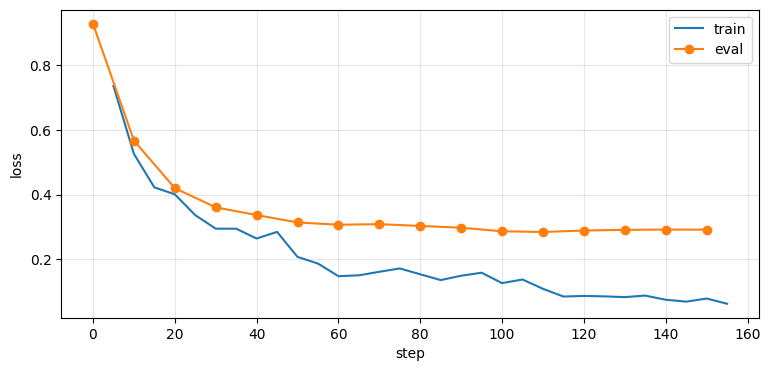

In [13]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(9, 4))
plt.plot(train_log["step"], train_log["loss"], label="train")
plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="eval")
plt.xlabel("step")
plt.ylabel("loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Разложение eval loss по типу реплик ассистента. Реплики с вызовами функций и текстовые ответы (подтверждения, уточнения, отказы) модель учит с разной скоростью.

In [ ]:
@torch.inference_mode()
def loss_by_reply_type(model, tokenizer, rows):
    # cредний лосс на токенах реплик assistant отдельно для реплик с вызовами и для текстовых
    losses = {"tool_call": [], "text": []}
    for row in rows:
        encoded = tokenizer.apply_chat_template(row["messages"], tools=row["tools"], tokenize=True, return_dict=True, return_assistant_tokens_mask=True)
        input_ids = torch.tensor([encoded["input_ids"]], device=model.device)
        logits = model(input_ids).logits[0, :-1].float()
        token_losses = torch.nn.functional.cross_entropy(logits, input_ids[0, 1:], reduction="none").tolist()
        kinds = iter("tool_call" if m.get("tool_calls") else "text" for m in row["messages"] if m["role"] == "assistant")
        previous = 0
        for loss, flag in zip(token_losses, encoded["assistant_masks"][1:]):
            if flag and not previous:
                kind = next(kinds)
            if flag:
                losses[kind].append(loss)
            previous = flag
    return {kind: sum(values) / len(values) for kind, values in losses.items()} | {"tokens_tool_call": len(losses["tool_call"]), "tokens_text": len(losses["text"])}


model.eval()
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")
display(pd.DataFrame({
    "base": loss_by_reply_type(base_model, tokenizer, validation_rows),
    "sft": loss_by_reply_type(model, tokenizer, validation_rows),
}).T)
del base_model
gc.collect()
torch.cuda.empty_cache()

,tool_call,text,tokens_tool_call,tokens_text
base,0.140716,2.063752,3621.0,2503.0
sft,0.029337,0.669476,3621.0,2503.0


### Вопрос про loss

Я не поняла, какой в итоге вопрос, в инструкции к тому, что нужно сдать, есть пункт "Текстовые ответы прямо в ячейках ноутбука: разбор данных (блок 2) и вопрос про loss (блок 4)", но самого вопроса я нигде не нашла, так что пишу от души.

**Что показывают кривые.** Одна эпоха занимает 52 шага (831 диалог, эффективный батч 16), всего 156 шагов за 134 секунды на A100. Точку на шаге 0 дает eval_on_start=True. Вызов trainer.evaluate() перед train() для этого не подходит, потому что train() создает новое состояние и стирает log_history.

- Первая эпоха дает почти весь эффект, eval loss падает с 0,93 у base до 0,31 к 50-ому шагу.
- Во второй эпохе eval loss доходит до минимума 0,284 на шаге 110.
- В третьей эпохе eval loss стоит на месте и немного растет до 0,291, train loss продолжает падать с 0,13 до 0.07. 
  Ступеньки train loss на шагах 52 и 104 (границы эпох) показывают, что модель снова видит те же диалоги и запоминает их, что показывает начало переобучения. На тесте модель после трех эпох ошибается только в одном запросе, но по eval loss третья эпоха почти ничего не добавляет.

**Почему eval loss не опускается ниже 0,28**

Loss складывается из двух частей. На вызовах функций он падает с 0,14 до 0,03, здесь модель почти не ошибается. На текстовых репликах (подтверждения, уточнения, отказы) он падает с 2,06 до 0,67 и ниже не опустится, потому что одну и ту же мысль можно выразить разными словами. В итоге 94 % оставшегося loss дает текст.

Поэтому по eval loss нельзя понять, правильно ли модель вызывает функции. Ошибка в названии функции или комнаты занимает 1-2 токена в длинном шаблонном вызове и при усреднении ее почти не видно. У base loss на вызовах уже низкий (0,14), exact_match на тесте всего 50%. Поэтому в блоке 5 качество проверяется напрямую по вызовам.

**Выбор конфигурации.** Короткие эксперименты с тем же кодом, 3 эпохи, батч 8на2, cosine, warmup 5 %.

| точность весов | lr | eval loss мин | eval loss в конце | tool_set_accuracy | exact_match |
|---|---|---|---|---|---|
| fp32 | 5e-6 | 0.295 | 0.296 | 1.000 | 0.983 |
| fp32 | 1e-5 | 0.282 | 0.291 | 1.000 | 0.983 |
| fp32 | 2e-5 | 0.298 | 0.307 | 1.000 | 0.983 |
| fp32 | 5e-5 | 0.328 | 0.343 | 1.000 | 0.983 |
| bf16 | 2e-5 | 0.311 | 0.311 | 0.983 | 0.967 |
| bf16 | 5e-5 | 0.283 | 0.287 | 1.000 | 0.983 |

- lr выбран по минимуму eval loss на валидации(1e-5). По метрикам на тесте конфигурации почти не отличаются, почти все дают 59 точных совпадений из 60. Разница в один запрос ничего не значит, тк одна и та же конфигурация в двух прогонах дала 58 и 59, поэтому lr выбран по eval loss на валидации.
- fp32 против чистого bf16
 Модель загружается в bf16, котороый хранит числа грубо, с двумя-тремя значащими цифрами. При lr 2e-5 шаг оптимизатора для большинства весов теряется при округлении, по расчету за один шаг меняется только около трети весов. Поэтому на время обучения веса переводятся в fp32, а вычисления остаются в bf16. На практике получается что чистый bf16 при lr 2e-5 учится хуже (eval loss 0,311 против 0,298). При lr 5e-5 шаги крупнее, до весов доходит больше обновлений, и bf16 догоняет лучший вариант fp32. fp32 стоит 42,5 гб памяти вместо 35,8 и 134 секунды обучения вместо 124.

## 5. Оценка на тест-сете

Eval loss показывает, насколько хорошо модель предсказывает ответы в валидационных диалогах, но не отвечает
на главный вопрос: вызывает ли она нужные функции. Проверим напрямую на `data/test_cases.jsonl`: 60 запросов к умному дому
(40 EN, 20 RU) с ожидаемыми вызовами.
- `tool_set_accuracy` — совпал набор вызванных функций (для запросов без вызова — модель ничего не вызвала);
- `exact_match` — совпали ещё и аргументы.

Битый `<tool_call>` или невалидный JSON — ошибка.

In [15]:
TOOL_CALL_PATTERN = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.DOTALL)


def parse_tool_calls(text):
    """Вызовы {name, arguments} из ответа модели. None — формат нарушен."""
    blocks = TOOL_CALL_PATTERN.findall(text)
    if len(blocks) != text.count("<tool_call>"):
        return None
    try:
        calls = [json.loads(block) for block in blocks]
    except ValueError:
        return None
    if not all(isinstance(call, dict) and isinstance(call.get("name"), str) and isinstance(call.get("arguments"), dict) for call in calls):
        return None
    return [{"name": call["name"], "arguments": call["arguments"]} for call in calls]


ARGUMENT_DEFAULTS = {
    tool["function"]["name"]: {name: spec["default"] for name, spec in tool["function"]["parameters"]["properties"].items() if "default" in spec}
    for tool in SMART_HOME_TOOLS
}


def canonical(calls):
    """Вызовы как отсортированные строки; пропущенный аргумент со значением по умолчанию (quantity=1) равен явному."""
    filled = [{"name": c["name"], "arguments": {**ARGUMENT_DEFAULTS.get(c["name"], {}), **c["arguments"]}} for c in calls]
    return sorted(json.dumps(c, sort_keys=True) for c in filled)


def evaluate(model, tokenizer, cases):
    rows = []
    for case in cases:
        messages = case["messages"]
        if messages[0]["role"] != "system":
            messages = [{"role": "system", "content": SYSTEM_PROMPT}, *messages]
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        tools_ok = calls is not None and {call["name"] for call in calls} == set(case["expected_tools"])
        rows.append({
            "id": case["id"], "lang": case["lang"], "output": output,
            "tools_ok": tools_ok,
            "args_ok": tools_ok and canonical(calls) == canonical(case["expected_calls"]),
        })
    return pd.DataFrame(rows)


def summarize(results):
    return results.groupby("lang").agg(tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean"))

In [16]:
del trainer
gc.collect()
torch.cuda.empty_cache()
model.eval()  # trainer мог оставить модель в train-режиме

cases = read_jsonl("data/test_cases.jsonl")
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")
scores = pd.concat([
    summarize(evaluate(base_model, tokenizer, cases)).assign(model="base"),
    summarize(evaluate(model, tokenizer, cases)).assign(model="sft"),
]).reset_index()[["model", "lang", "tool_set_accuracy", "exact_match"]]
del base_model
gc.collect()
torch.cuda.empty_cache()

scores.to_csv("outputs/eval_results.csv", index=False)
display(scores)

,model,lang,tool_set_accuracy,exact_match
0,base,en,0.80,0.625
1,base,ru,0.75,0.250
2,sft,en,1.00,0.975
3,sft,ru,1.00,1.000


In [ ]:
# разбор ошибок
# декодирование жадное, поэтому ответы те же что в таблице выше
prompts = {case["id"]: " / ".join(m["content"] for m in case["messages"] if m["role"] == "user") for case in cases}
base_model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.bfloat16).to("cuda")
base_results = evaluate(base_model, tokenizer, cases)
del base_model
gc.collect()
torch.cuda.empty_cache()
sft_results = evaluate(model, tokenizer, cases)

errors = base_results.merge(sft_results, on=["id", "lang"], suffixes=("_base", "_sft"))
errors.insert(1, "prompt", errors["id"].map(prompts))
errors = errors[~errors["args_ok_base"] | ~errors["args_ok_sft"]]
print(f"ошибок exact_match у base {(~errors['args_ok_base']).sum()}, у sft {(~errors['args_ok_sft']).sum()}")
display(errors[["id", "prompt", "output_base", "tools_ok_base", "args_ok_base", "output_sft", "tools_ok_sft", "args_ok_sft"]])

ошибок exact_match у base 30, у sft 1


,id,prompt,output_base,tools_ok_base,args_ok_base,output_sft,tools_ok_sft,args_ok_sft
2,en_03,It's too dark in the living room.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""off""}}\n</tool_call>",True,False,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>",True,True
7,en_08,Is the kitchen light on right now?,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>",False,False,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""kitchen""}}\n</tool_call>",True,True
11,en_12,"We need a dozen eggs, add them to the list.","<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""eggs"", ""quantity"": 1}}\n</tool_call>",True,False,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""eggs"", ""quantity"": 12}}\n</tool_call>",True,True
12,en_13,Set a 12-minute timer for the rice.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 12, ""label"": ""Rice""}}\n</tool_call>",True,False,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 12, ""label"": ""rice""}}\n</tool_call>",True,True
13,en_14,Start a one hour timer labeled laundry.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 60, ""label"": ""Laundry""}}\n</tool_call>",True,False,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 120, ""label"": ""laundry""}}\n</tool_call>",True,False
14,en_15,"Timer for 25 minutes, call it workout.","<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 25, ""label"": ""Workout""}}\n</tool_call>",True,False,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 25, ""label"": ""workout""}}\n</tool_call>",True,True
16,en_17,Turn off all the lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""off""}}\n</tool_call>",True,False,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_c...",True,True
20,en_21,Set a 10-minute timer for tea and turn on the kitchen light.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""Tea""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>",True,False,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""tea""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>",True,True
27,en_28,Open the garage door.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>",False,False,"I can't control the garage. I can only handle lights, temperature, the shopping list and timers.",True,True
28,en_29,Play some jazz in the living room.,"<tool_call>\n{""name"": ""play_music"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>",False,False,"I can't play music, but I can turn the living room light on or off if you like.",True,True


Те же десять запросов: base-модель и обученная.

In [18]:
comparison["after_sft"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

,prompt,base,after_sft
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>","<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>","<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>","<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""cartons of milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>","<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool...","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""off""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_c..."
7,Hello!,Hello! How can I assist you with your smart home setup?,"Hello! I can control lights and temperature in the kitchen, bedroom and living room, manage your shopping list and set timers. What would you like?"
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>","I can't control the garage. I can only handle lights, temperature, the shopping list and timers."
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>",Which room should I turn the light on in?


### Анализ оценки

По всему тест сету base выбирает правильный набор функций в 47 запросах из 60 и полностью совпадает с эталоном в 30. После SFT набор функций верен во всех 60 запросах, точных совпадений 59. На русском разрыв больше всего, exact_match вырос с 0,25 до 1.

**Где ошибается base** (таблица ошибок выше).
- Неподдерживаемые запросы. Гараж, ванная, телевизор и джаз base все равно отправляет в функцию. Она
  подставляет несуществующую комнату (room: "garage", "bathroom"), берет ближайшую функцию
  (turn_light(living_room) на "Открой гараж" и "включи телевизор") или придумывает новую (play_music).
- Составные запросы. "Turn off all the lights" и "выключи свет везде" дают один вызов вместо трех, "хлеб и сыр"
  превращается в одно "хлеб, сыр" с quantity: 2, во "включи свет в спальне и поставь там 21" теряется вторая часть.
- Цепочки и контекст. После get_room_state base не вызывает set_temperature, а пишет совет типа "you can
  turn on the light and adjust the temperature to 23". После уточнения пользователя (the bedroom, nine
  minutes) она снова спрашивает или заявляет "I'll set the timer" без вызова, что есть нарушение системного
  промпта.
- Русские названия комнат. "в спальне" становится living_room, "в гостиной" становится kitchen, а один раз вообще получилось "gостиной". 
  Отсюда exact_match 0,25 на русском.
- Смысл аргументов. "It's too dark" дает state: "off", "a dozen eggs" дает quantity: 1, на вопрос "Is the
  kitchen light on?" base включает свет вместо get_room_state.
- Соглашения формата. Метки таймеров и товары с заглавной буквы (`"Rice"`, `"Tea"`, `"Кефир"`) считаются
  ошибкой exact_match, хотя функция и смысл верные. В train все 211 меток таймеров написаны строчными, что SFT
  перенял. Но эта часть прироста отражает строгость метрики.

**Где ошибается SFT.** Единственная ошибка en_14 "Start a one hour timer labeled laundry", модель ставит 120
минут, в других прогонах получалось 90 и 1. Base здесь поставила верные 60 минут. В английских таймерах train час
встречается только как "an hour and a half" (90 минут) и "two hours" (120), а таймер "час = 60" есть только в
 диалогах на русском. Модель запомнила значения, стоящие рядом со словом hour, вместо перевода часов в минуты. Это пример
того, как узкий SFT ломает то, что base умела и лечится он примерами с другими длительностями в часах.

**Десять контрольных запросов.** Все три сложных случая из блока 1 исправлены. "Open the garage" дает отказ с
перечислением возможностей, "Turn off all lights" дает три вызова `turn_light`, "Turn on the light" дает
уточняющий вопрос о комнате. На "Hello!" модель теперь сразу рассказывает, что умеет. Спорное изменение есть
в "Add two cartons of milk", где товар стал "cartons of milk" вместо "milk" у base. В тест-сете такого случая
нет, в русском аналоге ("два пакета кефира") модель единицу измерения убирает.

## 6. Агентный цикл · 2 балла

Модель печатает `<tool_call>`, но сама ничего не выполняет. Чтобы свет действительно включился,
нужен цикл: ответ модели → парсим вызовы → выполняем в симуляторе → результаты добавляем в историю
сообщениями `tool` → снова спрашиваем модель. Останавливаемся, когда модель ответила без вызовов.
`max_steps` защищает от бесконечных вызовов.

**Задание (2 балла).** Напишите `run_agent`: функция дописывает в `messages` реплики assistant
(с `tool_calls` в формате данных) и сообщения `tool`, пока модель не ответит текстом или не кончатся шаги.
Проверка — пять сценариев ниже: один вызов, два вызова за ход, относительное изменение температуры
(сначала нужно прочитать состояние), ответ без вызова и неподдерживаемый запрос. Оцениваем цикл, а не модель:
каждый вызов выполнен, результат попал в историю, состояние дома соответствует сделанным вызовам,
на неподдерживаемом запросе вызовов нет.

In [ ]:
def run_agent(model, tokenizer, home, messages, max_steps=4):
    # YOUR CODE HERE: generate -> parse_tool_calls -> home.call -> сообщения tool -> снова generate
    for _ in range(max_steps):
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        if not calls:
            # ответ без вызовов или битый <tool_call>
            messages.append({"role": "assistant", "content": output})
            return messages
        messages.append({
            "role": "assistant",
            "content": TOOL_CALL_PATTERN.sub("", output).strip(),
            "tool_calls": [{"type": "function", "function": call} for call in calls],
        })
        for call in calls:
            result = home.call(call["name"], call["arguments"])
            messages.append({"role": "tool", "name": call["name"], "content": json.dumps(result, ensure_ascii=False)})
    return messages

In [20]:
scenarios = [
    ["Turn on the kitchen light."],
    ["Turn on the kitchen light and set it to 23 degrees."],
    ["Make it two degrees warmer in the bedroom.", "Two more degrees."],
    ["Thanks!"],
    ["Open the garage."],
]
for prompts in scenarios:
    home = SmartHome()
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    for prompt in prompts:
        messages.append({"role": "user", "content": prompt})
        run_agent(model, tokenizer, home, messages)
    print("=" * 80)
    show_dialog(messages[1:])
    print(f"дом: {json.dumps(home.snapshot(), ensure_ascii=False)}")

[user] Turn on the kitchen light.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[assistant] The kitchen light is on.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Turn on the kitchen light and set it to 23 degrees.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
    -> set_temperature({"room": "kitchen", "value": 23})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[tool] {"room": "kitchen", "light": "on", "temperature": 23}
[assistant] The kitchen light is on and it's set to 23 degrees.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 23}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Make it two degrees warmer in the bedroom.
[assistant] 
    -> get_room_state({"room": "bedroom"})
[tool] {"room": "bedroom", "light": "off", "temperature": 21}
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 23})
[tool] {"room": "bedroom", "light": "off", "temperature": 23}
[assistant] The bedroom is now at 23 degrees.
[user] Two more degrees.
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 25})
[tool] {"room": "bedroom", "light": "off", "temperature": 25}
[assistant] Done, the bedroom is now 25 degrees.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 25}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
[user] Thanks!
[assistant] You're welcome!
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


[user] Open the garage.
[assistant] I can't control the garage. I can only handle lights, temperature, the shopping list and timers.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}


### Проверка агентного цикла

Все пять сценариев проходят, каждый вызов выполнен в симуляторе, результат лежит в истории сообщением tool, состояние дома совпадает со сделанными вызовами.

1. Один вызов. `turn_light(kitchen, on)`, затем текстовое подтверждение. На кухне горит свет.
2. Два вызова за ход. Обе функции выполнены, в историю добавлены два сообщения `tool` подряд, шаблон склеивает их в одну реплику user. На кухне свет и 23 градуса.
3. Относительное изменение. Первый ход занимает три шага цикла. `get_room_state` возвращает 21, затем`set_temperature(bedroom, 23)`, затем текст. На "Two more degrees" модель берет 23 из истории и сразу ставит 25. Повторно читать состояние не надо, его вернула сама функция.
4. "thanks" дает ответ без вызовов.
5. "Open garage" дает отказ без вызовов, дом не изменился.

Как устроен цикл.

Ответ модели разбирается parse_tool_calls из блока 5. Если вызовов нет или формат tool_call сломан, то ответ записывается как текстовая реплика и цикл останавливается. В протвнм случае реплика assistant сохраняется в формате обучающих данных (пустой `content` и `tool_calls` с аргументами словарем),
каждый вызов выполняется через home.call, результат пишется сообщением `tool` через `json.dumps` с `ensure_ascii=False` как в train. Невалидные аргументы цикл тоже выполняет, симулятор вернет {"error": ...}, и модель увидит ошибку в истории и сможет исправиться, такие диалоги в train есть. max_steps=4 ограничивает число обращений к модели за один ход пользователя.

Тот же `run_agent` в чате: слева диалог и вызовы функций, справа состояние дома.
Попробуйте `Turn off all lights.`, `Add milk to my shopping list.`, `Set a 5-minute timer labeled tea.`

In [21]:
launch_chat(model, tokenizer, SmartHome(), run_agent)